In [1]:
using QuantumCollocation
using NamedTrajectories
using TrajectoryIndexingUtils

using CairoMakie
using DelimitedFiles
using Distributions
using LinearAlgebra
pathof(QuantumCollocation)

"/home/andy/Documents/Research/JuliaPackages/StealthPICO/src/QuantumCollocation.jl"

In [2]:
# Operators 
const n_levels = 2
const at = create(n_levels)
const a = annihilate(n_levels)

const H_ops = Dict(
        "X" => a + at,
        "Y" => -im * (a - at),
        "Z" => I - 2 * at * a,
)

Dict{String, Matrix} with 3 entries:
  "Y" => ComplexF64[0.0-0.0im 0.0-1.0im; -0.0+1.0im 0.0-0.0im]
  "Z" => [1.0 -0.0; -0.0 -1.0]
  "X" => [0.0 1.0; 1.0 0.0]

In [3]:
# Time
T = 51
T_cr = 270
Δt = 2/9
times = 0:Δt:(T-1)*Δt
ecr_times = 0:Δt:(T_cr-1)*Δt
;

In [16]:
traj = load_traj("saved-pulses-2024-01-24/single_qubit_gateset_R1e-3.jld2");
default = load_traj("saved-pulses-2024-01-24/single_qubit_gateset_default.jld2");
ecr = load_traj("saved-pulses-2024-01-16/two_qubit_default.jld2");

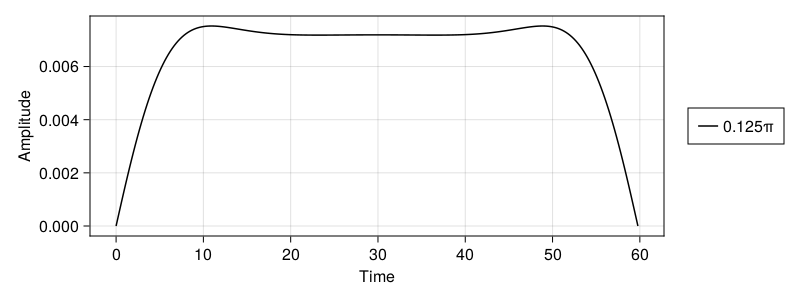

In [17]:
f = Figure(resolution = (800, 300))
ax = Axis(f[1, 1], xlabel = "Time", ylabel = "Amplitude")
for (i, row) in enumerate(eachrow(ecr[:a]))
    lines!(ax, ecr_times, row, color=:black, label="$(round(sum(row) * Δt / π, digits=3))π")
end
Legend(f[1,2], ax)
f

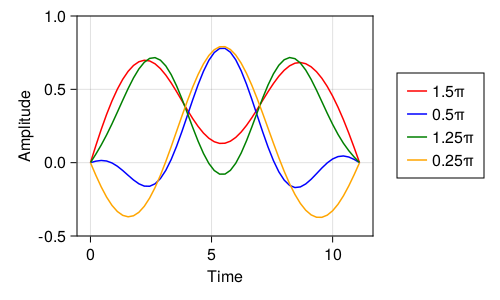

In [57]:
f = Figure(resolution = (500, 300))
ax = Axis(f[1, 1], xlabel = "Time", ylabel = "Amplitude")
colors = [:red, :blue, :green, :orange, :purple, :yellow]
for (i, row) in enumerate(eachrow(traj[:a]))
    lines!(ax, times, row, color=colors[i], label="$(round(sum(row) * Δt / π, digits=2))π")
end
Legend(f[1,2], ax)
ylims!(ax, (-0.5, 1.0))
f

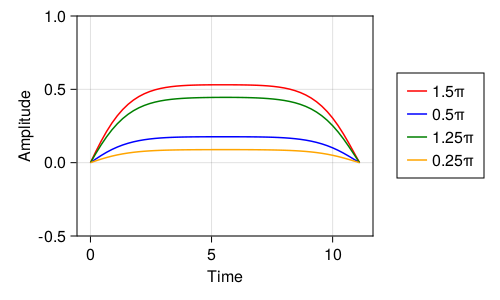

In [58]:
f = Figure(resolution = (500, 300))
ax = Axis(f[1, 1], xlabel = "Time", ylabel = "Amplitude")
colors = [:red, :blue, :green, :orange, :purple, :yellow]
for (i, row) in enumerate(eachrow(default[:a]))
    if i == 1 || i==3
        area = sum(row) * Δt / π
        row .= (area + 1) / area * row
    end
    lines!(ax, times, row, color=colors[i], label="$(round(sum(row) * Δt / π, digits=2))π")
end
Legend(f[1,2], ax)
ylims!(ax, (-0.5, 1.0))
f

# Check ZZ

In [40]:
H_drift = Dict(
    "H_0" => zeros(n_levels^2, n_levels^2),
    "H_ZZ" => kron_from_dict("ZZ", H_ops)
)
H_controls = [
    kron_from_dict("XI", H_ops),
    kron_from_dict("IX", H_ops),
]

sys_default = QuantumSystem(H_controls)

Ũ⃗_init = operator_to_iso_vec(kron_from_dict("II", H_ops))
;

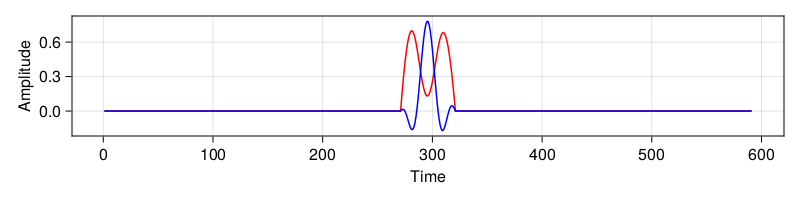

In [49]:
x_block = traj[:a][1:2, :]
ecr_block = zeros((2, T_cr))
pulse = hcat(ecr_block, x_block, ecr_block)

f = Figure(resolution = (800, 200))
ax = Axis(f[1, 1], xlabel = "Time", ylabel = "Amplitude")
for (i, row) in enumerate(eachrow(pulse))
    lines!(ax, row, color=colors[i], label="$(round(sum(row) * Δt / π, digits=2))π")
end
f

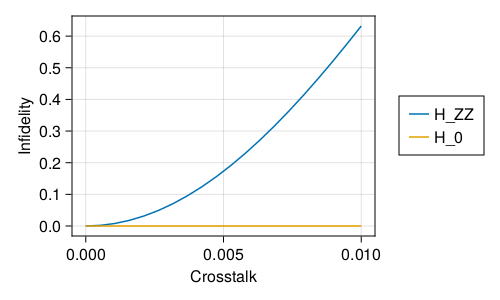

In [44]:
x_block = traj[:a][1:2, :]
ecr_block = zeros((2, T_cr))
pulse = hcat(ecr_block, x_block, ecr_block)

Ũ⃗_baseline = unitary_rollout(Ũ⃗_init, pulse, Δt, sys_default)[:, end]

f = Figure(resolution=(500, 300))
ζs = range(0, .01, 20)
ax = Axis(f[1, 1], xlabel="Crosstalk", ylabel="Infidelity")
for (i, (H_label, H)) in enumerate(H_drift)
    res = map(ζs) do ζ
        sys = QuantumSystem(ζ * H, H_controls)
        Ũ⃗_final = unitary_rollout(Ũ⃗_init, pulse, Δt, sys)[:, end]
        1-unitary_fidelity(Ũ⃗_final, Ũ⃗_baseline)
    end
    lines!(ax, ζs, res, label=H_label)
end
Legend(f[1,2], ax)
f

There is no way to avoid this as far as I can tell.